In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings('ignore')

df = pd.read_csv('insurance.csv')

df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [2]:
# EDA (Exploratary Data Analysis)

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


In [4]:
# So describe will be give result from only the numeric values that are provided in the data
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


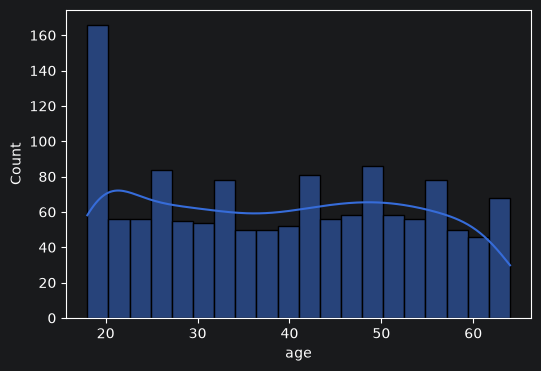

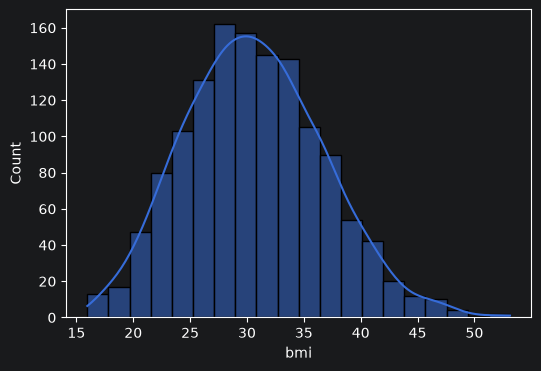

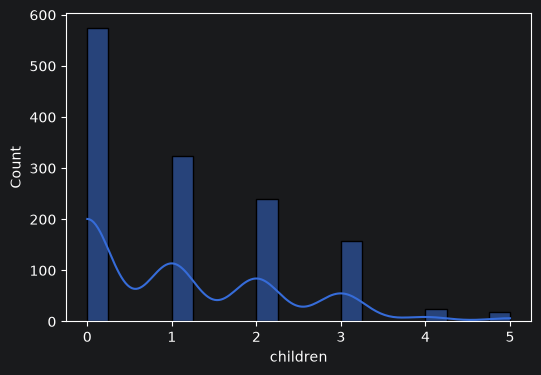

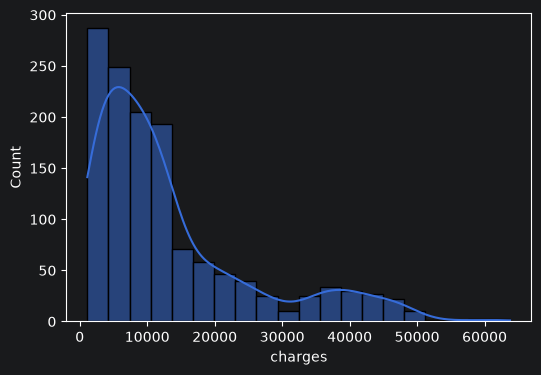

In [5]:
numeric_columns = ['age', 'bmi', 'children', 'charges']
for cols in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.histplot(data=df[cols], kde=True, bins=20)


<Axes: xlabel='children', ylabel='count'>

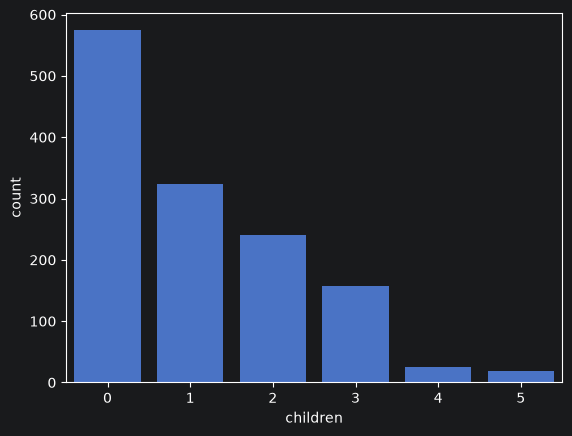

In [6]:
sns.countplot(x=df['children'])


<Axes: xlabel='sex', ylabel='count'>

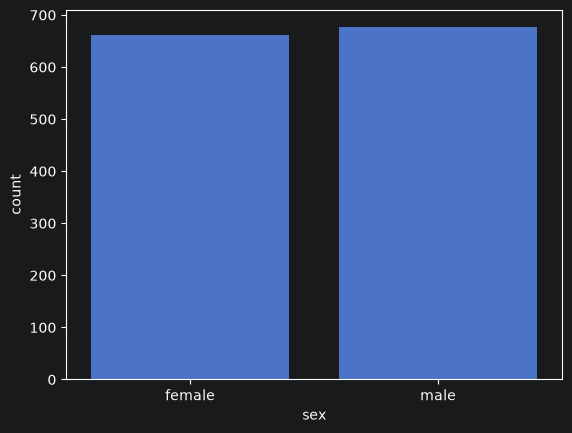

In [7]:
sns.countplot(x=df['sex'])


<Axes: xlabel='smoker', ylabel='count'>

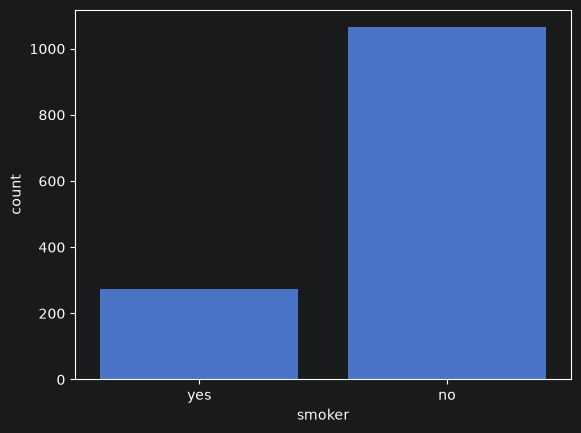

In [8]:
sns.countplot(x=df['smoker'])

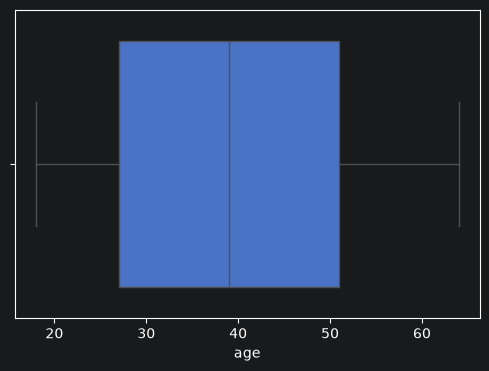

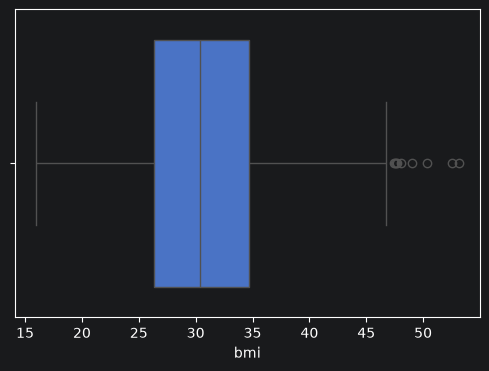

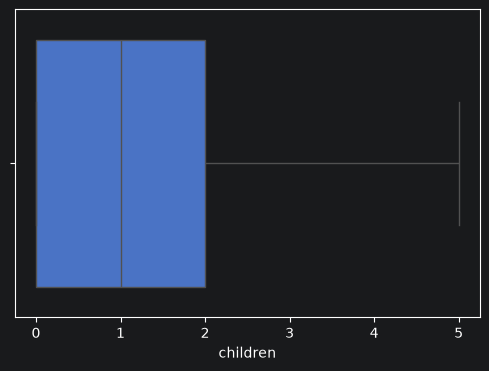

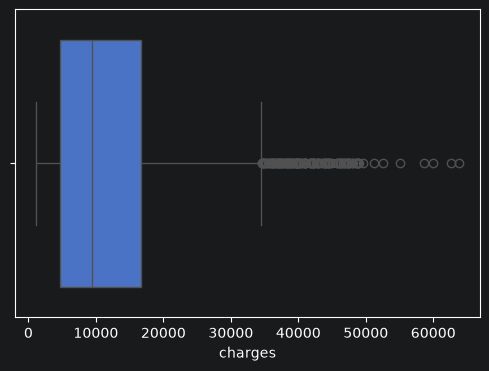

In [9]:
for col in numeric_columns:
    plt.figure(figsize=(6,4))
    sns.boxplot(x=df[col])

<Axes: >

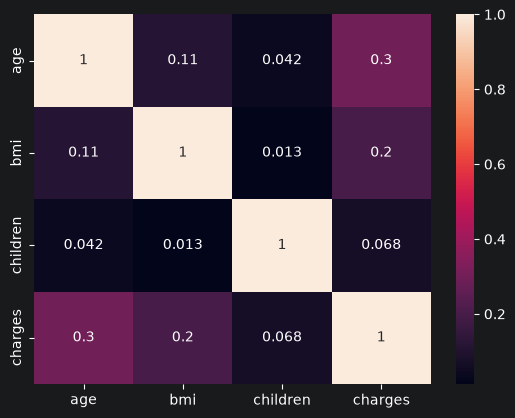

In [10]:
# So basically it will help to provide a overview relation of the data but only with the numeric values.
sns.heatmap(df.corr(numeric_only=True), annot=True)

# Data Cleaning Part
- Data must be copied because working on real file can cause some problems if we delete all the datas than it might cause the internal issues
- Then check null values if exist the fill the null values

In [11]:
df_cleaned = df.copy()
df_cleaned.head()


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [12]:
df_cleaned.drop_duplicates(inplace=True)


In [13]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [14]:
# Simply it will help to count the values that are present in the column
df_cleaned['sex'].value_counts()

sex
male      675
female    662
Name: count, dtype: int64

# Data Preprocessing for encoding
- It consists 2 types
- Label encoding: Simply converting or setting the value to the 0 and 1.
- One hot encoding: To convert the Categorical features and then encoding it to 0 and 1.

# Why it is needed.?
- To encode data
- To provide a meaningful data to the models by which results became better

In [15]:
# Label encoding
df_cleaned['sex'] = df_cleaned['sex'].map({'male': 0 , 'female': 1})


In [16]:
df_cleaned['sex'].value_counts()

sex
0    675
1    662
Name: count, dtype: int64

In [17]:
df_cleaned['smoker'] = df_cleaned['smoker'].map({"no": 0, "yes": 1})


In [18]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


# One Hot Encoding
- Two ways to do it
1. Either just put 0,1,2,3.....n
2. Separate Categorical Feature and then encode it

In [19]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['region'], drop_first=True)


In [20]:
df_cleaned = df_cleaned.astype(int)

In [21]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest
0,19,1,27,0,1,16884,0,0,1
1,18,0,33,1,0,1725,0,1,0
2,28,0,33,3,0,4449,0,1,0
3,33,0,22,0,0,21984,1,0,0
4,32,0,28,0,0,3866,1,0,0


# Feature Engineering
- It needs to be done to be more precise
- To check which feature should we use for better result
- It will help to specify the required datasets for the model

In [22]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'],
    bins=[0,18.5,24.9,29.9,float('inf')],
    labels=['Underweight','Normal','Overweight','Obese']
)

In [23]:
df_cleaned = pd.get_dummies(df_cleaned, columns=['bmi_category'], drop_first=True)
df_cleaned = df_cleaned.astype(int)


In [24]:
df_cleaned.head()

,age,sex,bmi,children,smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,19,1,27,0,1,16884,0,0,1,0,1,0
1,18,0,33,1,0,1725,0,1,0,0,0,1
2,28,0,33,3,0,4449,0,1,0,0,0,1
3,33,0,22,0,0,21984,1,0,0,1,0,0
4,32,0,28,0,0,3866,1,0,0,0,1,0


In [25]:
from sklearn.preprocessing import StandardScaler

cols = ['age', 'bmi', 'children']
scaler = StandardScaler()
df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])


In [31]:
df_cleaned.rename(
    columns={
        'sex':'is_female',
        'smoker': 'is_smoker'
    }, inplace=True
)

df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northwest,region_southeast,region_southwest,bmi_category_Normal,bmi_category_Overweight,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0,1,0,1,0
1,-1.511647,0,0.462463,-0.079442,0,1725,0,1,0,0,0,1
2,-0.799350,0,0.462463,1.580143,0,4449,0,1,0,0,0,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,1,0,0,1,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,1,0,0,0,1,0


In [34]:
from scipy.stats import pearsonr

selected_features = [
    'age', 'bmi', 'children', 'is_female','is_smoker', 'region_northwest',
    'region_southeast','region_southwest', 'bmi_category_Normal','bmi_category_Overweight', 'bmi_category_Obese'
]

correlations = {
    feature: pearsonr(df_cleaned[feature], df_cleaned['charges'])[0]
    for feature in selected_features
}

correlation_df = pd.DataFrame(list(correlations.items()), columns=['Feature','Pearson Correlation'])
correlation_df.sort_values(by='Pearson Correlation', ascending=False)


,Feature,Pearson Correlation
4,is_smoker,0.787234
0,age,0.298309
10,bmi_category_Obese,0.200348
1,bmi,0.196236
6,region_southeast,0.073577
2,children,0.067390
5,region_northwest,-0.038695
7,region_southwest,-0.043637
3,is_female,-0.058046
8,bmi_category_Normal,-0.104042


In [35]:
# Categorical Features
cat_features = [
    'is_female','is_smoker', 'region_northwest',
    'region_southeast','region_southwest',
    'bmi_category_Normal','bmi_category_Overweight',
    'bmi_category_Obese'
]

In [44]:
from scipy.stats import chi2_contingency
import pandas as pd

aplha = 0.05

df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'],q=4,labels=False)
chi2_results = {}
for col in cat_features:
    contingency = pd.crosstab(df_cleaned[col], df_cleaned['charges_bin'])
    chi2_stat , p_val, _,_ = chi2_contingency(contingency)
    decision = 'Reject Null(keep Feature)' if p_val < aplha else 'Accept Null(Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic': chi2_stat,
        'p_value': p_val,
        'Decision': decision
    }




In [52]:
chi2_df  = pd.DataFrame(chi2_results).T

chi2_df = chi2_df.sort_values(by='p_value')
chi2_df

,chi2_statistic,p_value,Decision
is_smoker,848.219178,0.0,Reject Null(keep Feature)
region_southeast,15.998167,0.001135,Reject Null(keep Feature)
is_female,10.258784,0.01649,Reject Null(keep Feature)
bmi_category_Obese,8.515711,0.036473,Reject Null(keep Feature)
region_southwest,5.091893,0.165191,Accept Null(Drop Feature)
bmi_category_Overweight,4.25149,0.235557,Accept Null(Drop Feature)
bmi_category_Normal,3.708088,0.29476,Accept Null(Drop Feature)
region_northwest,1.13424,0.768815,Accept Null(Drop Feature)


In [54]:
final_df= df_cleaned[['age','is_female','bmi', 'children', 'is_smoker', 'charges', 'region_southeast', 'bmi_category_Obese']]
final_df.

,age,is_female,bmi,children,is_smoker,charges,region_southeast,bmi_category_Obese
0,-1.440418,1,-0.517949,-0.909234,1,16884,0,0
1,-1.511647,0,0.462463,-0.079442,0,1725,1,1
2,-0.799350,0,0.462463,1.580143,0,4449,1,1
3,-0.443201,0,-1.334960,-0.909234,0,21984,0,0
4,-0.514431,0,-0.354547,-0.909234,0,3866,0,0
...,...,...,...,...,...,...,...,...
1333,0.767704,0,-0.027743,1.580143,0,10600,0,1
1334,-1.511647,1,0.135659,-0.909234,0,2205,0,1
1335,-1.511647,1,0.952670,-0.909234,0,1629,1,1
1336,-1.297958,1,-0.844753,-0.909234,0,2007,0,0
